# Predicting lineup OFF_RATING and DEF_RATING
**Eclipse Analytics | NBA research | Topic B**

Picks up the dataset prepared in `modeling.ipynb` and answers the questions left open
there:

1. Which features are worth using — average box scores, average play-type percentages,
   the `STD_` columns, cluster counts, and `GP` / `POSS` / `MIN`?
2. Does normalising the values help?
3. Which model and hyper-parameters give the best results? (decision tree and others)
4. Is 1,476 lineups enough, or should the possession threshold come down?

**Targets: `OFF_RATING` and `DEF_RATING`**, modelled separately.

### The headline, before the detail
* **`avg_box` alone — 12 average box-score columns — is the best feature set.** Adding
  play types, `STD_` spreads or cluster counts makes cross-validated performance *worse*,
  not better.
* **Ridge beats every tree model**, including a tuned decision tree. An untuned decision
  tree scores **R² ≈ −0.9**: worse than predicting the mean.
* **Offence is partly predictable, defence much less so.** Best held-out R²: ORTG ≈ 0.14,
  DRTG ≈ 0.10.
* **Lowering the possession threshold does not help.** More rows, but each is a noisier
  measurement of the same thing.
* **How you split matters more than which model you pick.** Lineups from one roster share
  up to four of five players, so a random train/test split leaks near-duplicates.

### Code layout
All computation lives in `lineup_modeling.py` (unit tested in
`tests/test_lineup_modeling.py`). `scripts/model_ortg_drtg.py` runs the same experiments
from the command line. This notebook is the narrative version, with charts.

## 0. Setup

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV, GroupKFold, KFold, cross_val_score
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor, plot_tree

ROOT = Path.cwd() if (Path.cwd() / "lineup_modeling.py").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
import lineup_modeling as lm

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 80)
RANDOM_STATE, N_SPLITS, TEST_SEASON = 42, 5, "2025-26"

lineup_path, player_path = lm.data_paths(ROOT)
print("lineups:", lineup_path.name, "| players:", player_path.name)
lineups_raw = pd.read_csv(lineup_path)
players_raw = pd.read_csv(player_path)
print("raw lineups:", lineups_raw.shape, "| raw players:", players_raw.shape)

lineups: lineups_five_seasons.csv | players: full_data.csv
raw lineups: (10000, 51) | raw players: (2204, 145)


## 1. Build the modelling table

`lm.build_lineup_dataset` is a vectorised, tested reimplementation of
`create_lineup_dataset` from `modeling.ipynb`. It reproduces the same **1,476 lineups**
at `POSS >= 100`, with three fixes:

* **`TOV_PCT` does not exist** in `full_data.csv` — the real column is `TM_TOV_PCT`. The
  prototype filtered feature lists to existing columns, so the turnover feature was
  silently dropped and never reached the model. Here a bad column name raises.
* **All-zero synergy rows mean "no play-type data", not "never ran this play".**
  Averaging those zeros drags a lineup's play-type profile toward zero. They become
  `NaN`, and `N_PLAYTYPE_MISSING` records how many members were affected.
* **Joins are on `(PLAYER_ID, SEASON)`**, so a 2021-22 profile can never attach to a
  2024-25 lineup.

In [2]:
data = lm.build_lineup_dataset(lineups_raw, players_raw, min_poss=100)
data["GROUP"] = data.TEAM.astype(str) + "_" + data.SEASON.astype(str)

print("modelling table:", data.shape, " (modeling.ipynb reported 1476 rows)")
print("all five members matched:", (data.MATCHED_PLAYERS == 5).all())
print("lineups missing play-type data for a member:", (data.N_PLAYTYPE_MISSING > 0).sum())
print("rows per season:", data.SEASON.value_counts().sort_index().to_dict())
print("teams:", data.TEAM.nunique())
display(data[["GROUP_ID", "SEASON", "TEAM", "POSS", "OFF_RATING", "DEF_RATING",
              "AVG_USG_PCT", "STD_USG_PCT", "AVG_TS_PCT"]].head())

modelling table: (1476, 79)  (modeling.ipynb reported 1476 rows)
all five members matched: True
lineups missing play-type data for a member: 1
rows per season: {'2021-22': 313, '2022-23': 311, '2023-24': 302, '2024-25': 289, '2025-26': 261}
teams: 30


,GROUP_ID,SEASON,TEAM,POSS,OFF_RATING,DEF_RATING,AVG_USG_PCT,STD_USG_PCT,AVG_TS_PCT
0,-201145-203115-203932-203999-1628420-,2021-22,DEN,1589,121.3,111.8,0.2082,0.052792,0.6042
1,-101108-203109-1626164-1628969-1629028-,2021-22,PHX,1577,116.4,109.0,0.2044,0.060807,0.5962
2,-201144-202711-203497-1626220-1628378-,2021-22,UTA,1395,117.1,110.5,0.2040,0.074016,0.6166
3,-201143-203935-1627759-1628369-1629057-,2021-22,BOS,911,118.8,94.2,0.2098,0.081101,0.6022
4,-201976-1626156-1626157-1629020-1630162-,2021-22,MIN,906,120.2,107.4,0.2092,0.064728,0.5790


In [3]:
sets = lm.feature_sets(data.columns)
for name, cols in sets.items():
    print(f"{name:20s} {len(cols):3d} features")
print()
for k, v in lm.CLUSTER_LABELS_PLAYSTYLE.items():
    print(f"  CLUSTER_{k}: {v}")
print("\n(labels from cluster_descriptions_and_players.txt on the past-5-seasons branch;"
      "\n clusters 0 and 2 are noted there as heavily overlapping)")

avg_box               12 features
avg_box_playtype      30 features
plus_std              60 features
plus_clusters         66 features
plus_usage            69 features

  CLUSTER_0: Interior / two-way big
  CLUSTER_1: Primary ball handler
  CLUSTER_2: Interior big (less defensive)
  CLUSTER_3: Off-ball role player / defensive wing
  CLUSTER_4: Spot-up specialist
  CLUSTER_5: Off-ball shooter

(labels from cluster_descriptions_and_players.txt on the past-5-seasons branch;
 clusters 0 and 2 are noted there as heavily overlapping)


## 2. How much of ORTG / DRTG is learnable at all?

Before tuning anything, it is worth knowing the ceiling. A lineup's rating is an average
over `POSS` possessions, so its sampling variance falls roughly as `1/POSS`:

$$\mathrm{Var}(\text{observed} \mid POSS) = \mathrm{Var}(\text{true}) + \frac{k}{POSS}$$

Fitting that across possession bins separates genuine spread in lineup quality
(intercept) from measurement noise (slope). **`reliability` is the share of observed
variance that is real — an approximate ceiling on any model's R².**

In [4]:
rows = []
for thr in [200, 150, 100, 75, 50, 25]:
    d = lm.build_lineup_dataset(lineups_raw, players_raw, min_poss=thr)
    for target in lm.TARGETS:
        rel = lm.rating_reliability(d, value_col=target)
        rows.append({"POSS >=": thr, "n lineups": len(d), "target": target,
                     "median POSS": round(rel["median_poss"]),
                     "SD(true)": rel["sd_true"],
                     "SD(observed)": d[target].std(),
                     "reliability": rel["reliability"]})
reliability = pd.DataFrame(rows)
display(reliability.round(3))

,POSS >=,n lineups,target,median POSS,SD(true),SD(observed),reliability
0,200,535,OFF_RATING,310,5.366,8.148,0.433
1,200,535,DEF_RATING,310,3.565,7.601,0.214
2,150,828,OFF_RATING,232,5.122,8.912,0.322
3,150,828,DEF_RATING,232,2.550,8.668,0.082
4,100,1476,OFF_RATING,163,4.583,10.463,0.190
5,100,1476,DEF_RATING,163,3.620,10.164,0.125
6,75,2213,OFF_RATING,122,3.248,11.949,0.072
7,75,2213,DEF_RATING,122,0.000,11.888,0.000
8,50,4102,OFF_RATING,79,4.964,14.079,0.119
9,50,4102,DEF_RATING,79,3.055,14.318,0.044


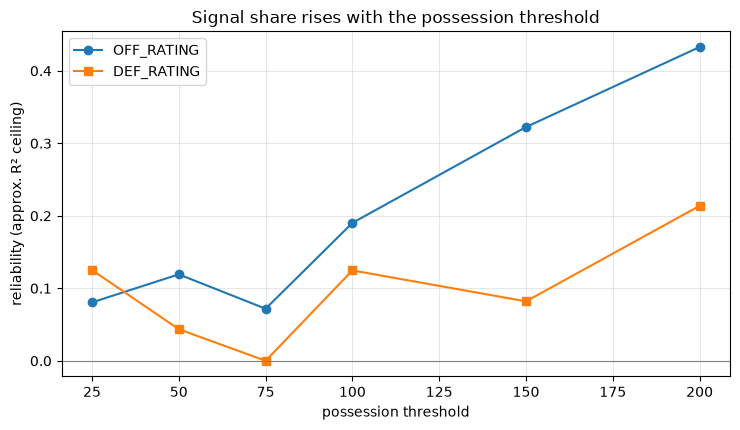

In [5]:
fig, ax = plt.subplots(figsize=(7.5, 4.4))
for target, marker in zip(lm.TARGETS, ("o", "s")):
    sub = reliability[reliability.target == target].sort_values("POSS >=")
    ax.plot(sub["POSS >="], sub["reliability"], marker=marker, label=target)
ax.set(xlabel="possession threshold", ylabel="reliability (approx. R² ceiling)",
       title="Signal share rises with the possession threshold")
ax.axhline(0, color="grey", lw=.8)
ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

Two things to take from this:

* **Offence carries more signal than defence at every threshold.** A lineup's offensive
  rating depends mostly on its own five players; its defensive rating depends heavily on
  scheme, matchups and who the opponent chose to attack.
* **The reliability estimate is itself noisy** — it is an OLS fit on a dozen binned
  variances, and at `POSS >= 75` the defensive estimate collapses to zero, which is an
  artefact of the fit rather than a real discontinuity. The robust part is the *trend*:
  a higher threshold means more signal per row.

At `POSS >= 100` the ceiling is roughly **0.19 for ORTG and 0.13 for DRTG**. An R² of
0.14 should be read against that, not against 1.0.

## 3. The split matters more than the model

Lineups from one roster overlap heavily — two lineups can share four of five players. A
random `train_test_split` puts near-duplicates on both sides, so the model is partly
being tested on rosters it already memorised.

Everything from here uses **`GroupKFold` with team-season as the group**, so a roster is
never split across folds.

In [6]:
def cv_r2(model, X, y, groups, grouped=True):
    cv = (GroupKFold(n_splits=N_SPLITS) if grouped
          else KFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE))
    return float(np.mean(cross_val_score(
        model, X, y, groups=groups if grouped else None, cv=cv, scoring="r2")))

candidates = {
    "DecisionTree (untuned)": DecisionTreeRegressor(random_state=RANDOM_STATE),
    "DecisionTree (depth 4)": DecisionTreeRegressor(
        max_depth=4, min_samples_leaf=20, random_state=RANDOM_STATE),
    "Ridge (alpha=10)": make_pipeline(StandardScaler(), Ridge(alpha=10.0)),
    "kNN (k=25)": make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=25)),
    "RandomForest": RandomForestRegressor(n_estimators=400, min_samples_leaf=10,
                                          random_state=RANDOM_STATE, n_jobs=-1),
    "HistGradientBoosting": HistGradientBoostingRegressor(
        max_depth=3, learning_rate=0.05, max_iter=300, random_state=RANDOM_STATE),
}

cols = sets["plus_clusters"]
rows = []
for name, model in candidates.items():
    for target in lm.TARGETS:
        rows.append({"model": name, "target": target,
                     "random KFold R2": cv_r2(model, data[cols], data[target],
                                              data.GROUP, grouped=False),
                     "GroupKFold R2": cv_r2(model, data[cols], data[target],
                                            data.GROUP, grouped=True)})
split_cmp = pd.DataFrame(rows)
split_cmp["inflation"] = split_cmp["random KFold R2"] - split_cmp["GroupKFold R2"]
display(split_cmp.round(4))

,model,target,random KFold R2,GroupKFold R2,inflation
0,DecisionTree (untuned),OFF_RATING,-0.8175,-0.8925,0.0750
1,DecisionTree (untuned),DEF_RATING,-0.9999,-1.0641,0.0643
2,DecisionTree (depth 4),OFF_RATING,0.0135,0.0602,-0.0467
3,DecisionTree (depth 4),DEF_RATING,-0.0355,-0.0988,0.0633
4,Ridge (alpha=10),OFF_RATING,0.1189,0.1004,0.0185
5,Ridge (alpha=10),DEF_RATING,0.0722,0.0321,0.0401
6,kNN (k=25),OFF_RATING,0.0871,0.0573,0.0298
7,kNN (k=25),DEF_RATING,0.0238,0.0102,0.0136
8,RandomForest,OFF_RATING,0.1247,0.1188,0.0059
9,RandomForest,DEF_RATING,0.0542,0.0272,0.0269


The inflation is modest here (roughly 0.01–0.07) but almost always in the same direction,
and it costs nothing to avoid. The more striking number is the **untuned decision tree at
R² ≈ −0.9** — far worse than predicting the mean. That is the direct answer to "is the
model overfitting?": an unconstrained tree on 1,476 noisy rows memorises the training set
completely.

## 4. Which features earn their place?

This is the ablation that answers the feature questions directly. The sets are nested:

| set | contents |
|---|---|
| `avg_box` | 12 average box-score / advanced columns |
| `avg_box_playtype` | + 18 average play-type shares |
| `plus_std` | + the `STD_` spread of every column |
| `plus_clusters` | + the six archetype counts |
| `plus_usage` | + `MIN`, `POSS`, `GP` |

In [7]:
rows = []
for target in lm.TARGETS:
    for name, cols_ in sets.items():
        for mname in ("Ridge (alpha=10)", "RandomForest"):
            rows.append({"target": target, "feature set": name,
                         "n features": len(cols_), "model": mname,
                         "GroupKFold R2": cv_r2(candidates[mname], data[cols_],
                                                data[target], data.GROUP)})
ablation = pd.DataFrame(rows)
for target in lm.TARGETS:
    print(f"--- {target} ---")
    display(ablation[ablation.target == target]
            .pivot(index=["feature set", "n features"], columns="model",
                   values="GroupKFold R2").round(4))

--- OFF_RATING ---


,model,RandomForest,Ridge (alpha=10)
feature set,n features,,
avg_box,12,0.1275,0.1575
avg_box_playtype,30,0.1294,0.1461
plus_clusters,66,0.1188,0.1004
plus_std,60,0.1191,0.1099
plus_usage,69,0.1226,0.1139


--- DEF_RATING ---


,model,RandomForest,Ridge (alpha=10)
feature set,n features,,
avg_box,12,0.0245,0.0685
avg_box_playtype,30,0.0127,0.0466
plus_clusters,66,0.0272,0.0321
plus_std,60,0.0267,0.0331
plus_usage,69,0.0366,0.0616


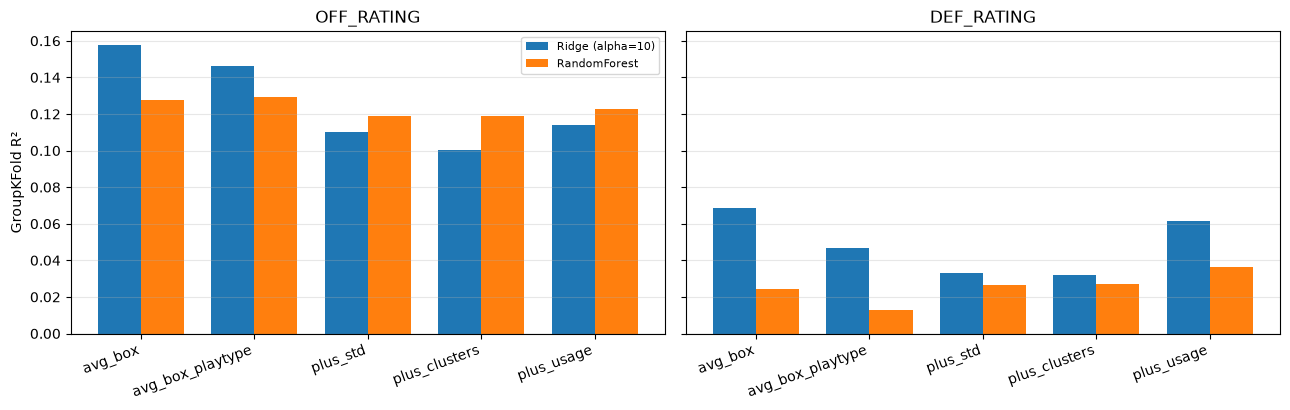

In [8]:
order = ["avg_box", "avg_box_playtype", "plus_std", "plus_clusters", "plus_usage"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for ax, target in zip(axes, lm.TARGETS):
    sub = ablation[ablation.target == target]
    width = 0.38
    xs = np.arange(len(order))
    for i, mname in enumerate(("Ridge (alpha=10)", "RandomForest")):
        vals = [sub[(sub["feature set"] == s) & (sub.model == mname)]["GroupKFold R2"].iloc[0]
                for s in order]
        ax.bar(xs + (i - 0.5) * width, vals, width, label=mname)
    ax.set_xticks(xs); ax.set_xticklabels(order, rotation=20, ha="right")
    ax.axhline(0, color="grey", lw=.8)
    ax.set_title(target); ax.grid(alpha=.3, axis="y")
axes[0].set_ylabel("GroupKFold R²"); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

### Answering the feature questions

**Use the average box scores. That is essentially the whole model.** `avg_box` — just 12
columns — is the best or joint-best set for both targets. Everything added after it makes
cross-validated performance flat or worse.

* **Average play-type percentages: no measurable gain.** Slightly negative for Ridge.
  Worth knowing, because collecting the synergy data was real work. Two likely reasons:
  the shares are **compositional** (each player's offensive shares sum to 1, so one
  column per block is redundant), and a *lineup average* of play-type shares blurs
  exactly the distinction that makes a play type interesting — one elite isolation player
  and four who never isolate averages out to "mildly isolation-ish".
* **`STD_` columns: no gain, and they double the feature count.** Role *diversity*
  measured this way adds nothing over role *level* here. (`STD_USG_PCT` does rank highly
  in tree importances, so the idea is not dead — but as a single feature, not 30 of them.)
* **Cluster counts: no gain.** The six archetypes are largely recoverable from the
  box-score averages the model already has.
* **`GP` / `POSS` / `MIN`: leave them out.** They help defence slightly — and that is
  exactly the problem. **A lineup plays more minutes because it performed well**, so
  these encode the coach's hindsight, not a property of the five players. A model using
  them cannot score a lineup that has not played yet, which is the whole point.

The pattern is the classic small-sample one: with ~1,476 rows and a target that is mostly
noise, **every extra feature costs more in variance than it returns in signal.**

## 5. Does normalising help?

Only for models that measure distances or penalise coefficient size. Trees split on
thresholds within a single column, so a monotone rescaling cannot change them.

In [9]:
raw_models = {
    "Ridge (alpha=10)": Ridge(alpha=10.0),
    "kNN (k=25)": KNeighborsRegressor(n_neighbors=25),
    "DecisionTree (depth 4)": DecisionTreeRegressor(max_depth=4, min_samples_leaf=20,
                                                    random_state=RANDOM_STATE),
    "RandomForest": RandomForestRegressor(n_estimators=400, min_samples_leaf=10,
                                          random_state=RANDOM_STATE, n_jobs=-1),
}
cols = sets["plus_clusters"]
rows = []
for target in lm.TARGETS:
    for name, est in raw_models.items():
        rows.append({
            "target": target, "model": name,
            "raw": cv_r2(est, data[cols], data[target], data.GROUP),
            "StandardScaler": cv_r2(make_pipeline(StandardScaler(), est),
                                    data[cols], data[target], data.GROUP),
        })
scaling = pd.DataFrame(rows)
scaling["difference"] = scaling["StandardScaler"] - scaling["raw"]
display(scaling.round(4))

,target,model,raw,StandardScaler,difference
0,OFF_RATING,Ridge (alpha=10),0.0612,0.1004,0.0392
1,OFF_RATING,kNN (k=25),-0.0085,0.0573,0.0657
2,OFF_RATING,DecisionTree (depth 4),0.0602,0.0602,0.0000
3,OFF_RATING,RandomForest,0.1188,0.1188,0.0001
4,DEF_RATING,Ridge (alpha=10),0.0291,0.0321,0.0030
5,DEF_RATING,kNN (k=25),-0.0297,0.0102,0.0399
6,DEF_RATING,DecisionTree (depth 4),-0.0988,-0.0988,0.0000
7,DEF_RATING,RandomForest,0.0272,0.0273,0.0001


**Normalise for Ridge and kNN; it is irrelevant for the tree models.** It matters most
for kNN, where the raw feature scales are wildly different (`FG3A` is in attempts per
game, `TS_PCT` is a fraction) so unscaled distances are dominated by the largest-range
column. Since Ridge turns out to be the best model, scaling is part of the final pipeline.

## 6. Is 1,476 lineups enough? Lowering the possession threshold

The suggestion was to lower the threshold if the model looks like it is overfitting. It
does overfit — but adding rows this way does not fix it, because the new rows are noisier
measurements of the same quantity.

In [10]:
rows = []
for thr in [200, 150, 100, 75, 50, 25]:
    d = lm.build_lineup_dataset(lineups_raw, players_raw, min_poss=thr)
    d["GROUP"] = d.TEAM.astype(str) + "_" + d.SEASON.astype(str)
    s = lm.feature_sets(d.columns)
    for target in lm.TARGETS:
        rows.append({"POSS >=": thr, "n lineups": len(d), "target": target,
                     "SD(target)": d[target].std(),
                     "Ridge R2": cv_r2(candidates["Ridge (alpha=10)"],
                                       d[s["avg_box"]], d[target], d.GROUP),
                     "RandomForest R2": cv_r2(candidates["RandomForest"],
                                              d[s["avg_box"]], d[target], d.GROUP)})
threshold_tbl = pd.DataFrame(rows)
for target in lm.TARGETS:
    print(f"--- {target} (avg_box features) ---")
    display(threshold_tbl[threshold_tbl.target == target]
            .drop(columns="target").round(4).reset_index(drop=True))

--- OFF_RATING (avg_box features) ---


,POSS >=,n lineups,SD(target),Ridge R2,RandomForest R2
0,200,535,8.1476,0.1990,0.1180
1,150,828,8.9120,0.1866,0.1385
2,100,1476,10.4631,0.1575,0.1275
3,75,2213,11.9489,0.1157,0.0975
4,50,4102,14.0790,0.0791,0.0629
5,25,9180,18.1441,0.0510,0.0370


--- DEF_RATING (avg_box features) ---


,POSS >=,n lineups,SD(target),Ridge R2,RandomForest R2
0,200,535,7.6014,0.0499,0.0133
1,150,828,8.6675,0.0624,0.0101
2,100,1476,10.1644,0.0685,0.0245
3,75,2213,11.8880,0.0430,0.0288
4,50,4102,14.3179,0.0283,0.0120
5,25,9180,18.0937,0.0209,-0.0033


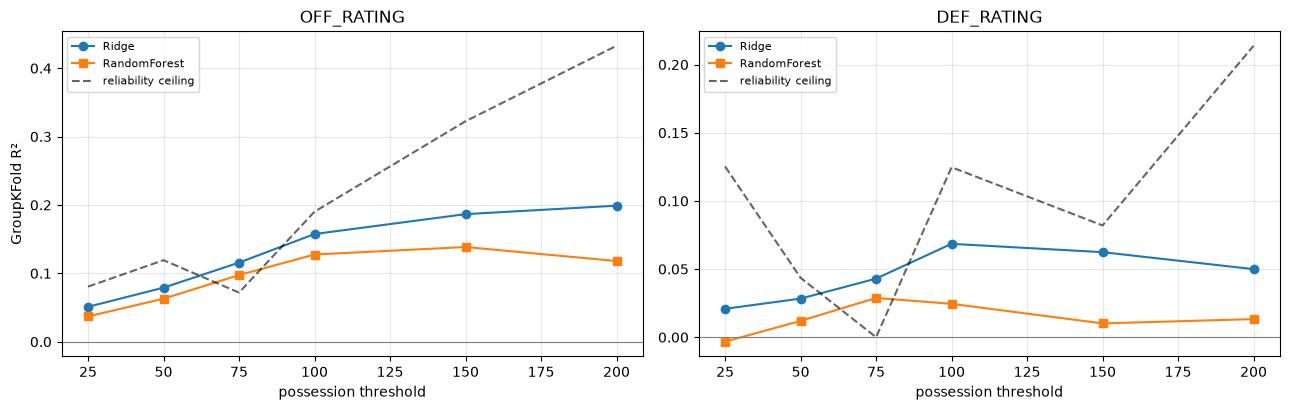

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, target in zip(axes, lm.TARGETS):
    sub = threshold_tbl[threshold_tbl.target == target].sort_values("POSS >=")
    ax.plot(sub["POSS >="], sub["Ridge R2"], "o-", label="Ridge")
    ax.plot(sub["POSS >="], sub["RandomForest R2"], "s-", label="RandomForest")
    rel = reliability[reliability.target == target].sort_values("POSS >=")
    ax.plot(rel["POSS >="], rel["reliability"], "k--", alpha=.6, label="reliability ceiling")
    ax.axhline(0, color="grey", lw=.8)
    ax.set(xlabel="possession threshold", title=target)
    ax.grid(alpha=.3); ax.legend(fontsize=8)
axes[0].set_ylabel("GroupKFold R²")
plt.tight_layout(); plt.show()

**Lowering the threshold makes the scores worse, and raising it makes them better.**
Going from `POSS >= 100` to `POSS >= 25` grows the sample from 1,476 to ~9,180 rows and
R² falls; going up to `POSS >= 200` shrinks it to ~535 rows and R² rises.

The model is not getting better or worse — **the target is.** `SD(target)` climbs from
about 8 to about 18 as the threshold drops, and almost all of that extra variance is
sampling noise that nothing can explain. The dashed reliability ceiling tracks the model
curves closely, which is the tell.

So: **1,476 lineups is not the binding constraint — target noise is.** More rows of a
noisier target does not help. If we want a better model, the lever is a cleaner target
(more possessions per lineup, opponent adjustment, or pooling a lineup across seasons),
not a lower threshold.

## 7. Tuning: feature set *and* hyper-parameters

Since section 4 shows the feature set matters as much as the model, it is tuned as an
explicit dimension rather than fixed. Selection is by `GroupKFold` R².

This runs the **same grid** as `scripts/model_ortg_drtg.py`, so the numbers here and
from the command line agree. It takes a few minutes.

In [12]:
cv = GroupKFold(n_splits=N_SPLITS)
searches = {
    "DecisionTree": (DecisionTreeRegressor(random_state=RANDOM_STATE),
                     {"max_depth": [2, 3, 4, 5, 6, 8, None],
                      "min_samples_leaf": [5, 10, 20, 40, 80],
                      "min_samples_split": [2, 10, 20],
                      "ccp_alpha": [0.0, 0.01, 0.1]}),
    # n_jobs=1 on the forest: GridSearchCV does the parallelising, and nesting
    # the two oversubscribes every core.
    "RandomForest": (RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=1),
                     {"n_estimators": [400], "max_depth": [4, 6, 8, None],
                      "min_samples_leaf": [5, 10, 20, 40],
                      "max_features": ["sqrt", 0.3, 1.0]}),
    "HistGradientBoosting": (HistGradientBoostingRegressor(random_state=RANDOM_STATE),
                             {"max_depth": [2, 3, 4], "learning_rate": [0.02, 0.05, 0.1],
                              "max_iter": [200, 500], "min_samples_leaf": [10, 30],
                              "l2_regularization": [0.0, 1.0]}),
    "Ridge": (make_pipeline(StandardScaler(), Ridge()),
              {"ridge__alpha": [0.1, 1, 10, 50, 100, 500, 1000]}),
}

best, best_cols, summary = {}, {}, []
for target in lm.TARGETS:
    for name, (est, grid) in searches.items():
        top = None
        for set_name in ("avg_box", "avg_box_playtype", "plus_clusters"):
            gs = GridSearchCV(est, grid, cv=cv, scoring="r2", n_jobs=-1)
            gs.fit(data[sets[set_name]], data[target], groups=data.GROUP)
            if top is None or gs.best_score_ > top[0]:
                top = (gs.best_score_, set_name, gs.best_params_, gs.best_estimator_)
        score, set_name, params, est_best = top
        best[(target, name)] = est_best
        best_cols[(target, name)] = sets[set_name]
        summary.append({"target": target, "model": name, "feature set": set_name,
                        "GroupKFold R2": score, "best params": str(params)})
    summary.append({"target": target, "model": "Baseline (mean)", "feature set": "-",
                    "GroupKFold R2": cv_r2(DummyRegressor(strategy="mean"),
                                           data[sets["avg_box"]], data[target],
                                           data.GROUP),
                    "best params": "-"})

tuning = pd.DataFrame(summary)
for target in lm.TARGETS:
    print(f"--- {target} ---")
    display(tuning[tuning.target == target].drop(columns="target")
            .sort_values("GroupKFold R2", ascending=False).round(4)
            .reset_index(drop=True))

--- OFF_RATING ---


,model,feature set,GroupKFold R2,best params
0,Ridge,avg_box,0.1578,{'ridge__alpha': 1}
1,RandomForest,avg_box,0.1354,"{'max_depth': None, 'max_features': 'sqrt', 'm..."
2,HistGradientBoosting,avg_box_playtype,0.1343,"{'l2_regularization': 0.0, 'learning_rate': 0...."
3,DecisionTree,avg_box_playtype,0.0920,"{'ccp_alpha': 0.0, 'max_depth': 3, 'min_sample..."
4,Baseline (mean),-,-0.0092,-


--- DEF_RATING ---


,model,feature set,GroupKFold R2,best params
0,Ridge,avg_box,0.0727,{'ridge__alpha': 1}
1,RandomForest,avg_box,0.0361,"{'max_depth': 8, 'max_features': 'sqrt', 'min_..."
2,HistGradientBoosting,avg_box,0.0266,"{'l2_regularization': 1.0, 'learning_rate': 0...."
3,Baseline (mean),-,-0.0009,-
4,DecisionTree,plus_clusters,-0.0140,"{'ccp_alpha': 0.0, 'max_depth': 2, 'min_sample..."


## 8. Held-out 2025-26

Cross-validation guided the choices, so a season the tuning never touched is the honest
final check. Train on 2021-22 … 2024-25, test on 2025-26.

In [13]:
train = data[data.SEASON != TEST_SEASON]
test = data[data.SEASON == TEST_SEASON]
print(f"train={len(train)}  test={len(test)}")

rows = []
for target in lm.TARGETS:
    base = train[target].mean()
    ss_tot = float(np.sum((test[target] - base) ** 2))
    rows.append({"target": target, "model": "Baseline (training mean)",
                 "holdout R2": 0.0,
                 "RMSE": lm.weighted_rmse(test[target], np.full(len(test), base))})
    for name in ("DecisionTree", "RandomForest", "HistGradientBoosting", "Ridge"):
        est, cols_ = best[(target, name)], best_cols[(target, name)]
        est.fit(train[cols_], train[target])
        pred = est.predict(test[cols_])
        rows.append({"target": target, "model": name,
                     "holdout R2": 1 - float(np.sum((test[target] - pred) ** 2)) / ss_tot,
                     "RMSE": lm.weighted_rmse(test[target], pred)})
holdout = pd.DataFrame(rows)
display(holdout.round(4))

train=1215  test=261


,target,model,holdout R2,RMSE
0,OFF_RATING,Baseline (training mean),0.0000,10.3272
1,OFF_RATING,DecisionTree,0.0563,10.0322
2,OFF_RATING,RandomForest,0.1414,9.5694
3,OFF_RATING,HistGradientBoosting,0.1313,9.6253
4,OFF_RATING,Ridge,0.1376,9.5904
5,DEF_RATING,Baseline (training mean),0.0000,10.5200
6,DEF_RATING,DecisionTree,-0.0077,10.5606
7,DEF_RATING,RandomForest,0.0720,10.1342
8,DEF_RATING,HistGradientBoosting,0.0622,10.1878
9,DEF_RATING,Ridge,0.1043,9.9563


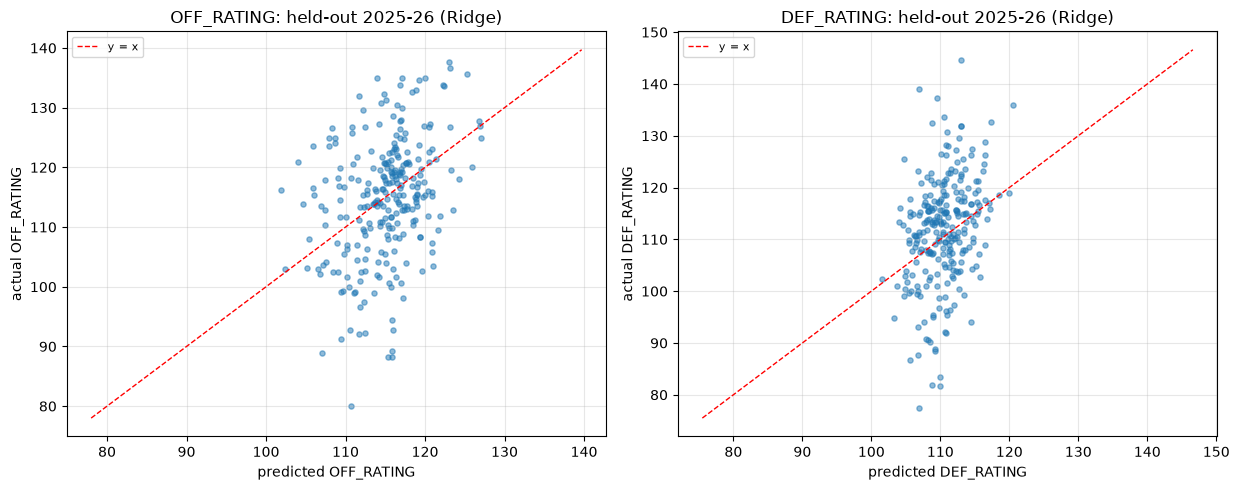

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 5))
for ax, target in zip(axes, lm.TARGETS):
    est, cols_ = best[(target, "Ridge")], best_cols[(target, "Ridge")]
    est.fit(train[cols_], train[target])
    pred = est.predict(test[cols_])
    ax.scatter(pred, test[target], s=14, alpha=.5)
    lo = min(pred.min(), test[target].min()) - 2
    hi = max(pred.max(), test[target].max()) + 2
    ax.plot([lo, hi], [lo, hi], "r--", lw=1, label="y = x")
    ax.set(xlabel=f"predicted {target}", ylabel=f"actual {target}",
           title=f"{target}: held-out {TEST_SEASON} (Ridge)")
    ax.legend(fontsize=8); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

Note how narrow the predicted range is compared with the actual range. That is correct
behaviour, not a bug: when most of the target is noise, a well-regularised model should
predict close to the mean and only move when the evidence is strong. The untuned decision
tree does the opposite — it spreads its predictions across the full range and is wrong.

## 9. What the models use

In [15]:
for target in lm.TARGETS:
    est, cols_ = best[(target, "RandomForest")], best_cols[(target, "RandomForest")]
    est.fit(data[cols_], data[target])
    imp = pd.Series(est.feature_importances_, index=cols_).sort_values(ascending=False)
    print(f"--- {target}: RandomForest importances (top 10) ---")
    display(imp.head(10).round(4).to_frame("importance"))

--- OFF_RATING: RandomForest importances (top 10) ---


,importance
AVG_TS_PCT,0.1606
AVG_EFG_PCT,0.1390
AVG_AST_PCT,0.0862
AVG_TM_TOV_PCT,0.0834
AVG_FG3_PCT,0.0787
AVG_USG_PCT,0.0755
AVG_FG3A,0.0752
AVG_OREB_PCT,0.0694
AVG_REB_PCT,0.0644
AVG_STL,0.0628


--- DEF_RATING: RandomForest importances (top 10) ---


,importance
AVG_USG_PCT,0.1150
AVG_TM_TOV_PCT,0.0975
AVG_BLK,0.0946
AVG_REB_PCT,0.0925
AVG_STL,0.0894
AVG_DREB_PCT,0.0893
AVG_EFG_PCT,0.0859
AVG_AST_PCT,0.0732
AVG_TS_PCT,0.0707
AVG_FG3A,0.0693


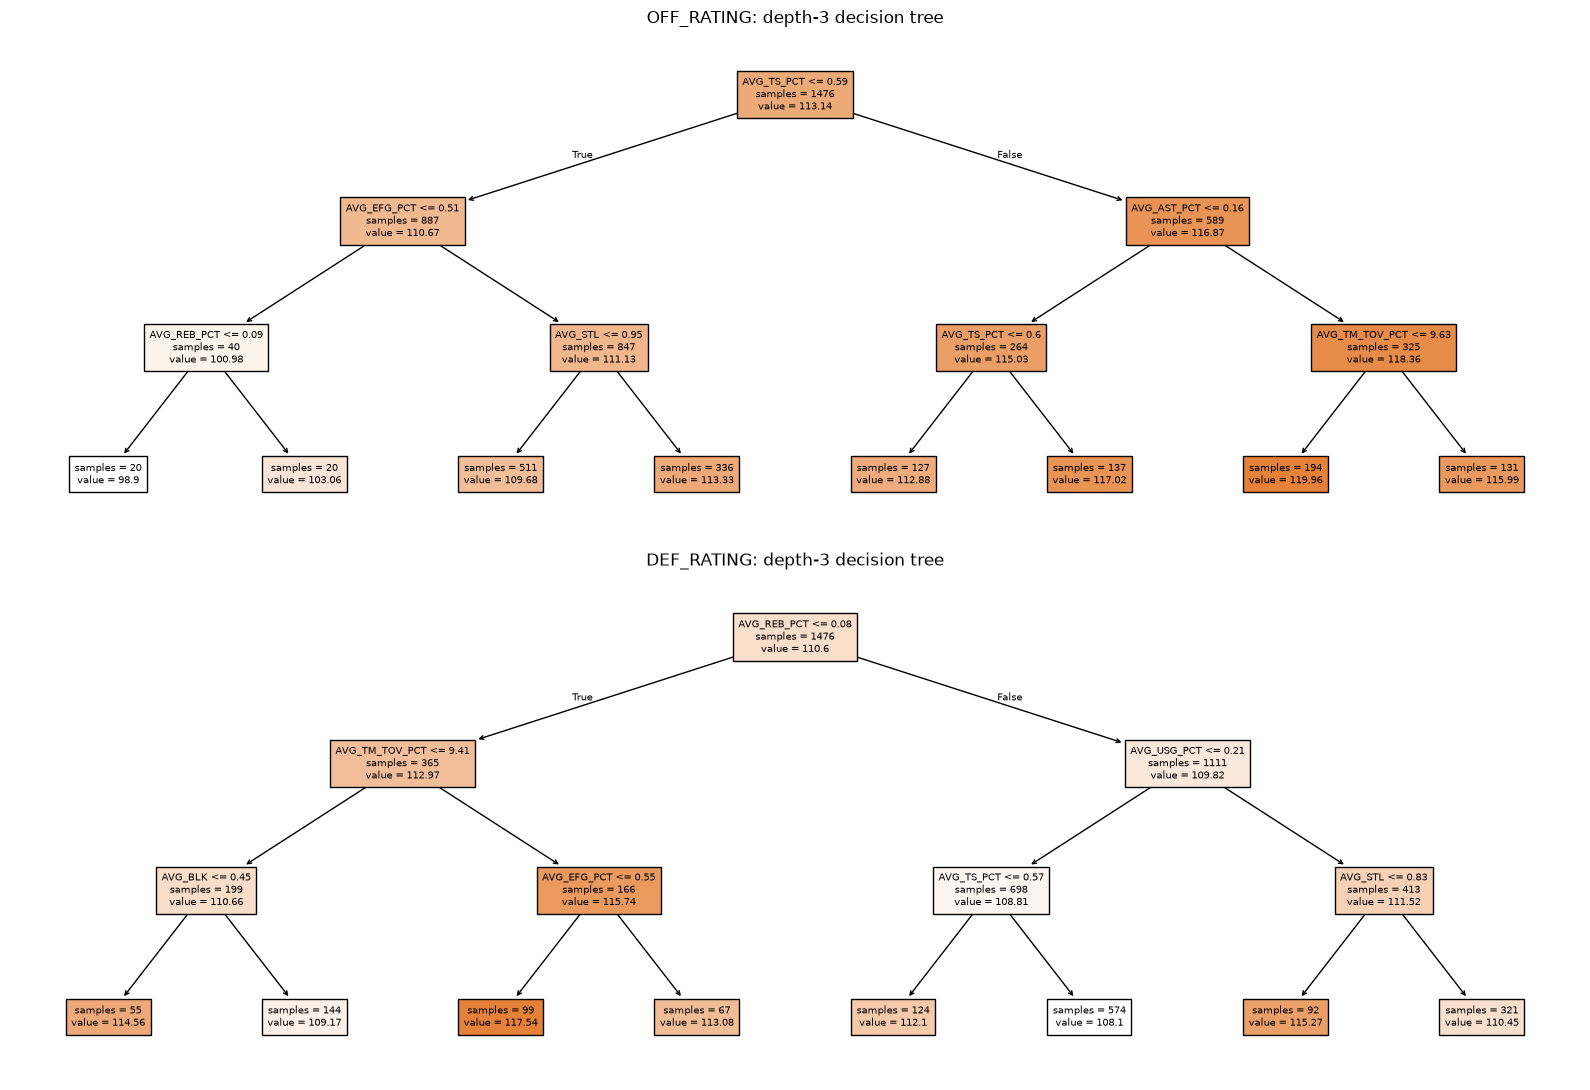

In [16]:
# A depth-3 tree on the box-score features - this is what the tuned decision
# tree settles on, and it is readable.
fig, axes = plt.subplots(2, 1, figsize=(16, 11))
for ax, target in zip(axes, lm.TARGETS):
    t = DecisionTreeRegressor(max_depth=3, min_samples_leaf=20,
                              random_state=RANDOM_STATE)
    t.fit(data[sets["avg_box"]], data[target])
    plot_tree(t, feature_names=sets["avg_box"], filled=True, fontsize=7,
              impurity=False, ax=ax, precision=2)
    ax.set_title(f"{target}: depth-3 decision tree")
plt.tight_layout(); plt.show()

For **OFF_RATING** the tree splits almost entirely on shooting efficiency —
`AVG_TS_PCT` and `AVG_EFG_PCT` dominate. That is talent, not chemistry: five efficient
scorers outscore five inefficient ones.

For **DEF_RATING** no feature stands out, which is consistent with the low reliability
and the weak scores. `STD_USG_PCT` ranking high for both targets is the one
composition-flavoured signal that keeps appearing.

Impurity importances are biased toward high-cardinality continuous features, so treat
these as a rough ranking rather than an effect size.

## 10. Reality check: are these scores a forecast?

Every feature so far is measured in the **same season** as the target, over possessions
that include the lineup's own. A player's `TS_PCT` partly reflects the very minutes being
predicted. Refitting with each member's **previous season** profile shows how much that
flatters the result.

In [17]:
seasons = sorted(players_raw.SEASON.unique())
nxt = {seasons[i]: seasons[i + 1] for i in range(len(seasons) - 1)}
prior_players = players_raw.copy()
prior_players["SEASON"] = prior_players["SEASON"].map(nxt)
prior_players = prior_players.dropna(subset=["SEASON"])

same = lm.build_lineup_dataset(lineups_raw, players_raw, min_poss=100)
lagged = lm.build_lineup_dataset(lineups_raw, prior_players, min_poss=100)
shared = set(zip(lagged.GROUP_ID, lagged.SEASON)) & set(zip(same.GROUP_ID, same.SEASON))
same = same[[k in shared for k in zip(same.GROUP_ID, same.SEASON)]].copy()
lagged = lagged[[k in shared for k in zip(lagged.GROUP_ID, lagged.SEASON)]].copy()
for f in (same, lagged):
    f["GROUP"] = f.TEAM.astype(str) + "_" + f.SEASON.astype(str)
print(f"lineups with a complete prior-season profile for all five: {len(shared):,}")

rows = []
for target in lm.TARGETS:
    for mname in ("Ridge (alpha=10)", "RandomForest"):
        for label, frame in (("same-season", same), ("prior-season", lagged)):
            c = lm.feature_sets(frame.columns)["avg_box"]
            rows.append({"target": target, "model": mname, "features": label,
                         "GroupKFold R2": cv_r2(candidates[mname], frame[c],
                                                frame[target], frame.GROUP)})
leak = pd.DataFrame(rows).pivot(index=["target", "model"], columns="features",
                                values="GroupKFold R2")
leak["drop"] = leak["same-season"] - leak["prior-season"]
display(leak.round(4))

lineups with a complete prior-season profile for all five: 795


features                     prior-season  same-season    drop
target     model                                              
DEF_RATING RandomForest           -0.0156       0.0231  0.0387
           Ridge (alpha=10)       -0.0105       0.0482  0.0588
OFF_RATING RandomForest            0.0048       0.0814  0.0766
           Ridge (alpha=10)        0.0467       0.0990  0.0523

**This is the most important table in the notebook.**

* **OFF_RATING survives, weakened.** R² falls from about 0.10 to about 0.05, so roughly
  half the apparent performance came from same-season information. A real but small
  forecasting signal remains.
* **DEF_RATING does not survive — it goes negative.** Using only information available
  before the season, these features predict lineup defensive rating *worse than the
  mean does*.

So the same-season numbers answer **"how well do these five players' profiles describe
what this lineup did?"** — a legitimate descriptive question. They do **not** answer
"could we have called it in advance". Only the prior-season column does, and for defence
the answer is currently no.

## 11. Conclusions and recommendations

### Direct answers
| Question | Answer |
|---|---|
| Normalise? | Yes for Ridge/kNN, irrelevant for trees. Ridge wins, so it is in the final pipeline. |
| Which features? | **Average box scores only** (12 columns). Play types, `STD_`, clusters add nothing. |
| `STD` of play types? | **Drop them.** No gain, and they double the feature count. |
| `GP` / `POSS` / `MIN`? | **Drop them.** They help slightly, but only because a lineup plays more *after* performing well. |
| Decision tree? | Works, but is the **weakest** model tried. Untuned: R² ≈ −0.9. Tuned (depth 3, `min_samples_leaf` 80): CV 0.09 for ORTG, **−0.01 for DRTG**. |
| Best model? | **Ridge on `avg_box`** (α = 1 once the feature count is down to 12). CV: 0.158 / 0.073. Held out: **ORTG 0.138, DRTG 0.104**. RandomForest ties on ORTG holdout (0.141) but loses on DRTG. |
| Is 1,476 enough? | Row count is not the constraint — **target noise is**. Lowering the threshold made results worse; raising it made them better. |

### Why the simplest model wins
With ~1,476 rows, a target that is ~80–90% sampling noise, and up to 69 correlated
features, there is very little signal to find and a great deal of variance to fit. Heavy
regularisation and few features is the right response. The ranking
Ridge > RandomForest > HistGB > DecisionTree is what that situation looks like.

### Recommended next steps
1. **Use `avg_box` + Ridge as the project baseline.** Anything more complex should have
   to beat it on `GroupKFold`.
2. **Model offence and defence separately, and expect different ceilings.** Treating
   `NET_RATING` as one target averages a learnable signal with an unlearnable one.
3. **Improve the target before the model.** Opponent adjustment, or pooling a lineup
   across seasons, would raise the ceiling more than any amount of tuning.
4. **Revisit the play-type features at the right granularity.** Averaging them across
   five players destroys their meaning. Max/min, or the share belonging to the lineup's
   highest-usage player, might work where the mean does not.
5. **Always report `GroupKFold`.** A random split quietly rewards memorising rosters.
6. **Quote prior-season numbers for anything described as prediction**, and same-season
   numbers only as description.